In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("deep")

In [2]:
df = pd.read_csv(
    "data/nifty_cleaned.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return_%,MA_50,MA_200,Year
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400,NaN,NaN,NaN,2016
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700,0.476776,NaN,NaN,2016
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000,0.022504,NaN,NaN,2016
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600,-0.240244,NaN,NaN,2016
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900,0.797464,NaN,NaN,2016


In [3]:
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate Range:")
print(df["Date"].min())
print(df["Date"].max())

(2483, 11)

Columns:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return_%', 'MA_50', 'MA_200', 'Year']

Date Range:
2016-06-01 00:00:00
2026-06-30 00:00:00


In [4]:
#...what we will do ....
# 1. Long-term growth
# 2. Volatility over time
# 3. Good years vs bad years
# 4. Market crashes & recovery
# 5. Seasonality
# 6. Risk characteristics

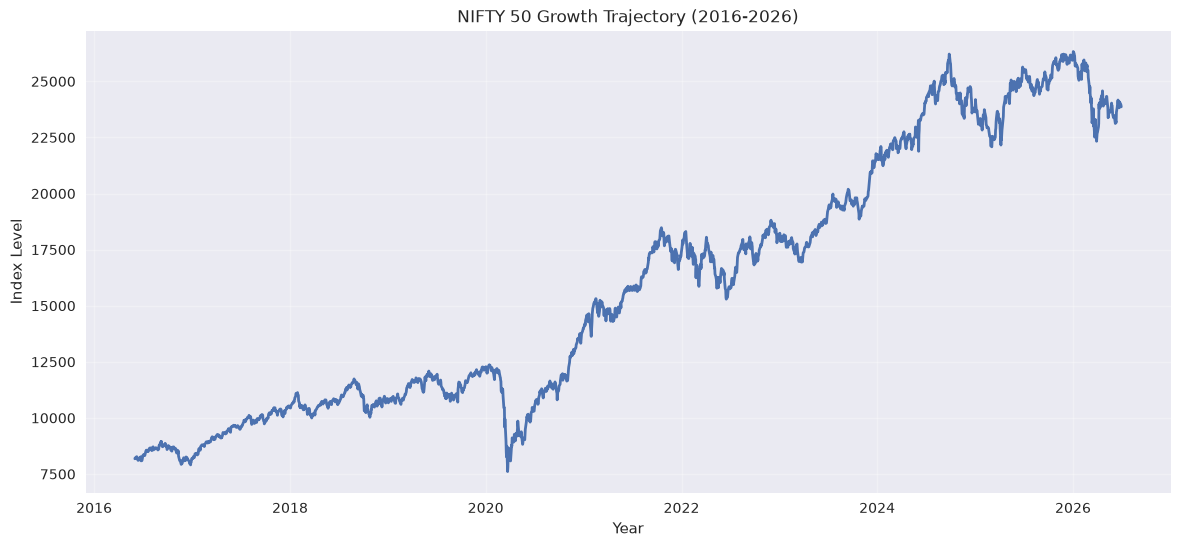

In [5]:
# 1. Long-term growth
plt.figure(figsize=(14,6))

plt.plot(
    df["Date"],
    df["Close"],
    linewidth=2
)

plt.title("NIFTY 50 Growth Trajectory (2016-2026)")
plt.xlabel("Year")
plt.ylabel("Index Level")

plt.grid(alpha=0.3)

plt.show()


In [6]:
# 2. Volatility over time
df["Volatility_30D"] = (
    df["Daily_Return_%"]
    .rolling(30)
    .std()
)

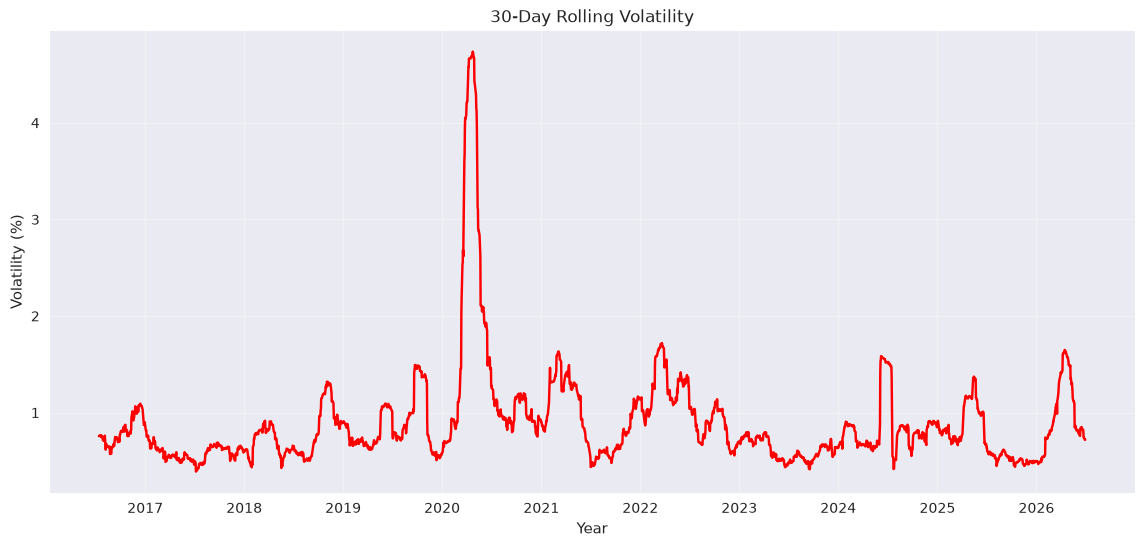

In [7]:
plt.figure(figsize=(14,6))

plt.plot(
    df["Date"],
    df["Volatility_30D"],
    color="red"
)

plt.title("30-Day Rolling Volatility")
plt.xlabel("Year")
plt.ylabel("Volatility (%)")

plt.grid(alpha=0.3)

plt.show()

In [8]:
#...Yearly returns....
yearly_returns = (
    df.groupby("Year")
      .apply(
          lambda x:
          (
              x["Close"].iloc[-1]
              /
              x["Close"].iloc[0]
              - 1
          )*100
      )
)

yearly_returns = yearly_returns.reset_index()
yearly_returns.columns = ["Year", "Return_%"]

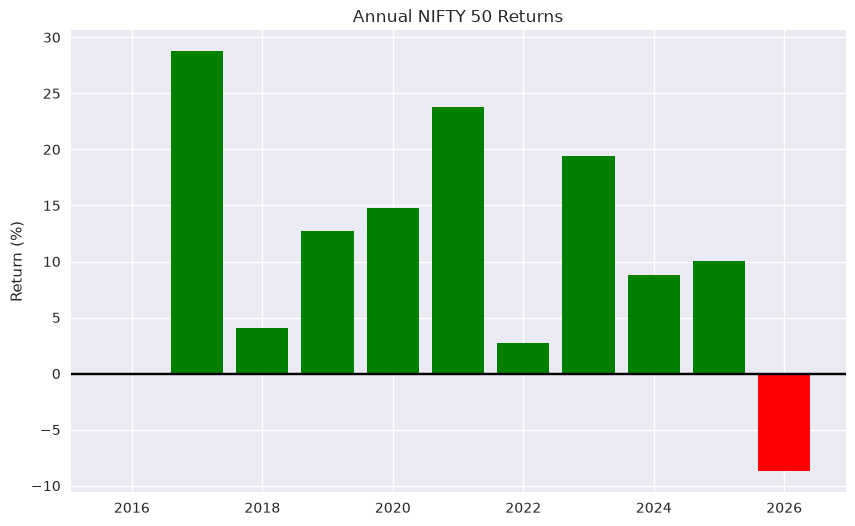

In [9]:
plt.figure(figsize=(10,6))

colors = [
    "green" if x > 0 else "red"
    for x in yearly_returns["Return_%"]
]

plt.bar(
    yearly_returns["Year"],
    yearly_returns["Return_%"],
    color=colors
)

plt.axhline(0,color="black")

plt.title("Annual NIFTY 50 Returns")
plt.ylabel("Return (%)")

plt.show()

In [10]:
#market fall from pervious 
running_max = df["Close"].cummax()

drawdown = (
    (df["Close"] - running_max)
    /
    running_max
)*100

df["Drawdown_%"] = drawdown

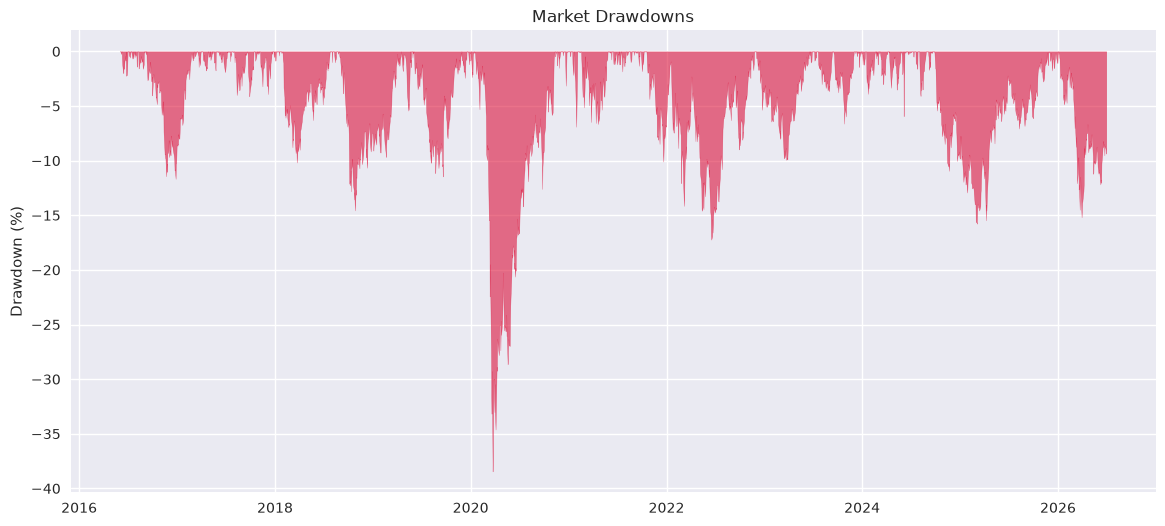

In [12]:
plt.figure(figsize=(14,6))

plt.fill_between(
    df["Date"],
    df["Drawdown_%"],
    0,
    color="crimson",
    alpha=0.6
)

plt.title("Market Drawdowns")
plt.ylabel("Drawdown (%)")

plt.show()

In [17]:
#monthy returns
df["Month"] = df["Date"].dt.month

monthly_returns = (
    df.groupby(["Year","Month"])["Daily_Return_%"]
      .sum()
      .reset_index()
)
heatmap_data = monthly_returns.pivot(
    index="Year",
    columns="Month",
    values="Daily_Return_%"
)

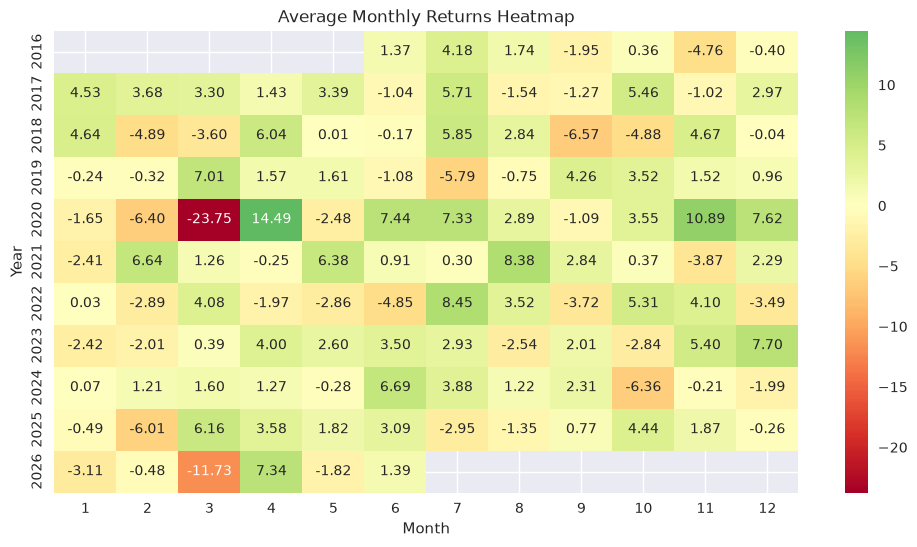

In [18]:
plt.figure(figsize=(12,6))

sns.heatmap(
    heatmap_data,
    cmap="RdYlGn",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Average Monthly Returns Heatmap")

plt.show()

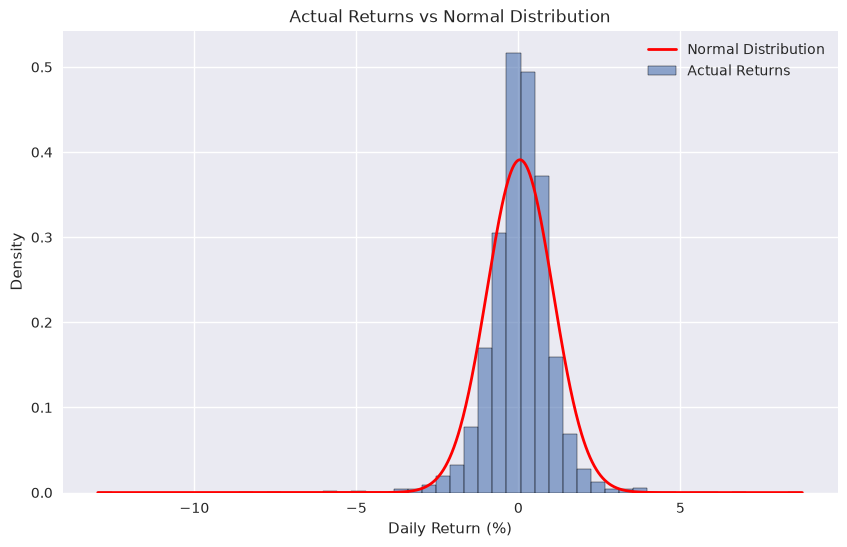

In [20]:
from scipy.stats import norm

returns = df["Daily_Return_%"].dropna()

mu = returns.mean()
sigma = returns.std()

x = np.linspace(
    returns.min(),
    returns.max(),
    1000
)

plt.figure(figsize=(10,6))

sns.histplot(
    returns,
    bins=50,
    stat="density",
    alpha=0.6,
    label="Actual Returns"
)

plt.plot(
    x,
    norm.pdf(x, mu, sigma),
    color="red",
    linewidth=2,
    label="Normal Distribution"
)

plt.title(
    "Actual Returns vs Normal Distribution"
)

plt.xlabel("Daily Return (%)")
plt.ylabel("Density")

plt.legend()

plt.show()

In [21]:
print("WEEK 2 SUMMARY")
print("- Loaded cleaned NIFTY 50 dataset")
print("- Performed advanced visualization and storytelling analysis")
print("- Analyzed long-term market growth trajectory")
print("- Examined rolling volatility patterns")
print("- Compared annual market performance")
print("- Investigated market drawdowns")
print("- Explored monthly return patterns")
print("- Analyzed return distribution characteristics")
print("- Identified key business and investment insights")

WEEK 2 SUMMARY
- Loaded cleaned NIFTY 50 dataset
- Performed advanced visualization and storytelling analysis
- Analyzed long-term market growth trajectory
- Examined rolling volatility patterns
- Compared annual market performance
- Investigated market drawdowns
- Explored monthly return patterns
- Analyzed return distribution characteristics
- Identified key business and investment insights
